In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import pyabc

from plotting_tools import * 

In [2]:
plot_path = f"../plots/case_fits"
os.makedirs(plot_path, exist_ok=True)

In [3]:
db_path = f"../../1_estimation/output/HEV_cases.db"
history = pyabc.History("sqlite:///" + db_path)

In [4]:
rows = []
for p in range(0, history.max_t + 1):
    particles = history.get_population(p).get_particles_by_model()[0]
    for particle in particles[:200]:
        rows.append({
            "distance": particle.distance,
            "population": (p + 1)
        })

df_dist = pd.DataFrame(rows)

all_pops = history.get_all_populations()
df = all_pops.T
samples = df.loc[df.index == "samples"]
samples = samples.transpose()
samples["population"] = range(0, history.max_t + 2, 1)
samples["Acceptance rate"] = 200 / samples["samples"] * 100  # 4.5, 2.3, 1.4%
samples["samples_scaled"] = samples["samples"] / 1e4
samples = samples.drop(0)

In [5]:
samples.tail()

,samples,population,Acceptance rate,samples_scaled
4,994,4,20.120724,0.0994
5,2232,5,8.960573,0.2232
6,4411,6,4.534119,0.4411
7,8544,7,2.340824,0.8544
8,13886,8,1.4403,1.3886


In [6]:
all_pops = pd.concat([all_pops, all_pops["population_end_time"].shift()], axis=1).dropna()
all_pops.columns = ["t", "end_time", "samples", "epsilon", "particles", "start_time"]
all_pops['diff_minutes'] = (all_pops['end_time'] - all_pops['start_time']).dt.total_seconds() / 60
print(all_pops)

   t                   end_time  samples   epsilon  particles  \
1  0 2025-11-11 17:37:37.708576      426  0.268938        200   
2  1 2025-11-11 18:42:12.348105      524  0.190338        200   
3  2 2025-11-11 19:53:26.977675      576  0.158754        200   
4  3 2025-11-11 21:55:58.301926      994  0.137217        200   
5  4 2025-11-12 02:29:30.159204     2232  0.124886        200   
6  5 2025-11-12 11:27:50.614988     4411  0.116712        200   
7  6 2025-11-13 04:50:24.167933     8544  0.111220        200   
8  7 2025-11-14 09:12:16.403071    13886  0.107777        200   

                  start_time  diff_minutes  
1 2025-11-11 16:44:10.105826     53.460046  
2 2025-11-11 17:37:37.708576     64.577325  
3 2025-11-11 18:42:12.348105     71.243826  
4 2025-11-11 19:53:26.977675    122.522071  
5 2025-11-11 21:55:58.301926    273.530955  
6 2025-11-12 02:29:30.159204    538.340930  
7 2025-11-12 11:27:50.614988   1042.559216  
8 2025-11-13 04:50:24.167933   1701.870586  


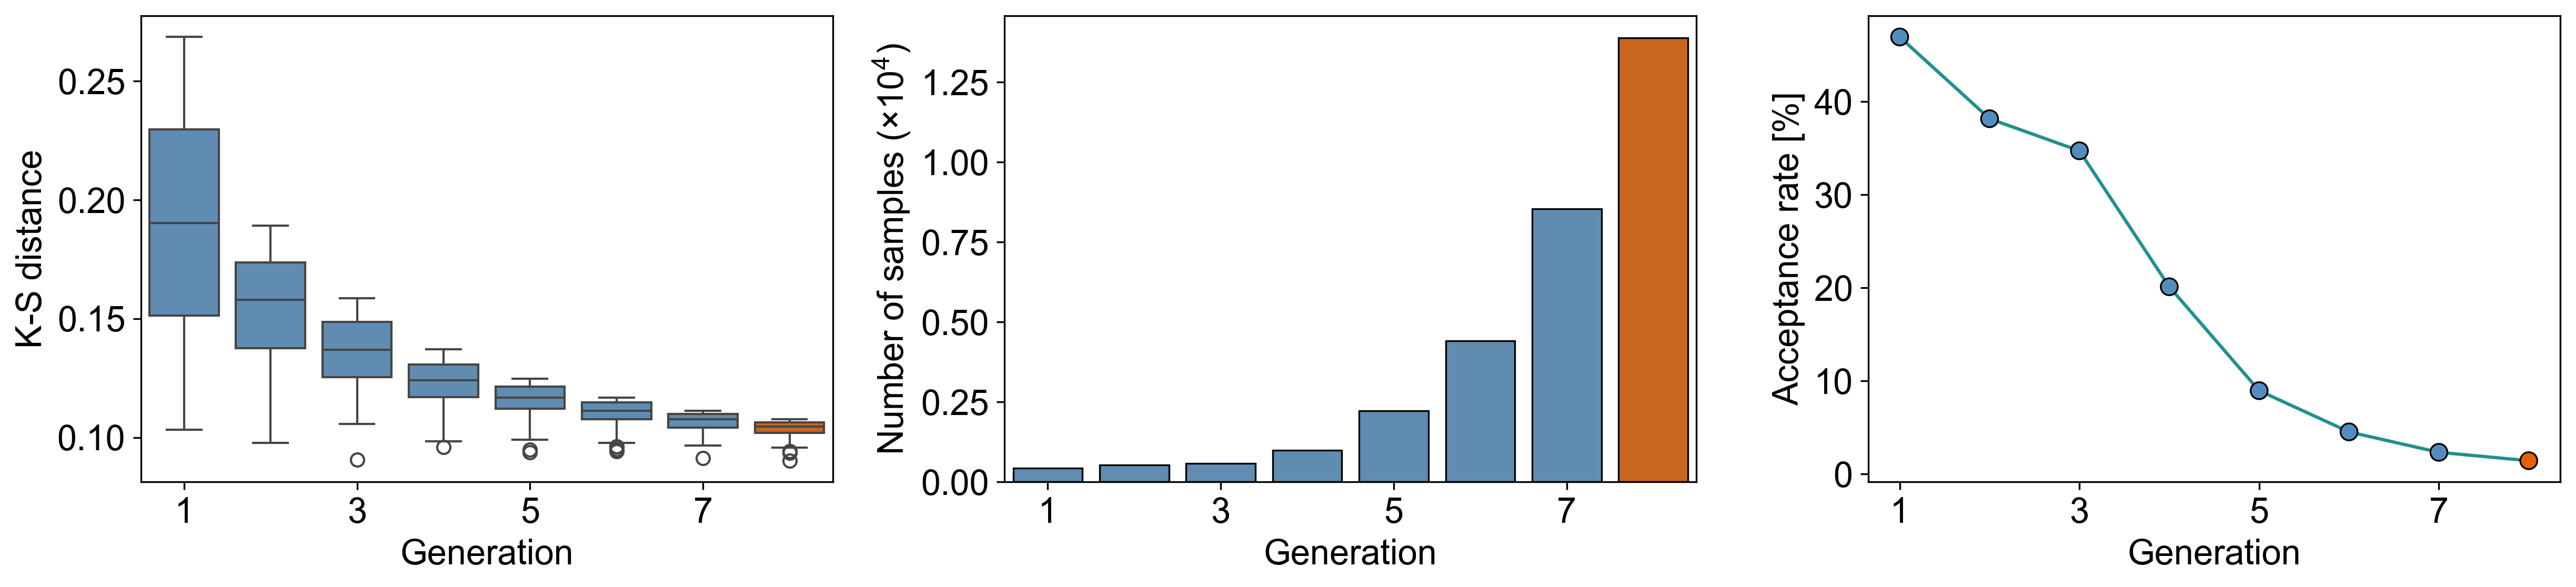

In [7]:
plt.style.use('default')
set_fontsize()

fig, axes = plt.subplots(figsize = (16.6,4), nrows=1, ncols=3, dpi=300)

unique_pops = sorted(df_dist["population"].unique())
palette = {pop: (orange if pop == df_dist["population"].max() else lightblue) for pop in unique_pops}

sns.boxplot(data = df_dist, x = "population", y = "distance", hue = "population", legend = False, palette = palette, ax = axes[0])
axes[0].set_ylabel("Calibration distance")
axes[0].set_xlabel("Generation")
axes[0].set_xticks(range(0, len(unique_pops), 2))

sns.barplot(data = samples, x = 'population', y = 'samples_scaled', hue = "population", legend = False, palette = palette, ax = axes[1])
for patch in axes[1].patches:
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
axes[1].set_ylabel(r"Number of samples ($\times 10^{4}$)")
axes[1].set_xlabel("Generation")
axes[1].set_xticks(range(0, len(unique_pops), 2))

means = (samples.groupby('population', as_index=False)['Acceptance rate'].mean().sort_values('population'))
axes[2].plot(means['population'], means['Acceptance rate'], linewidth=1.5, c = teal, zorder=1)
sns.scatterplot(data=samples, x='population', y='Acceptance rate', hue = "population", legend = False, ax = axes[2], palette = palette, marker='o', edgecolor='black', linewidth=0.8, s=60, zorder=2)
axes[2].set_xlabel("Generation")
axes[2].set_xticks(range(1, len(unique_pops) + 1, 2))
axes[2].set_ylabel("Acceptance rate [%]")

plt.tight_layout()
plt.savefig(f"{plot_path}/generations.png", dpi=300)
plt.show()

In [8]:
p = history.max_t

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["cases_nl"]):
        rows.append({
            "cases": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_nl = pd.DataFrame(rows)
sim_nl["Category"] = "Non-Emergency"

rows = []
particles = history.get_population(p).get_particles_by_model()[0]
for particle_id, particle in enumerate(particles[:200]):
    for d in np.atleast_1d(particle.sum_stat["cases_l"]):
        rows.append({
            "cases": d,
            "particle": particle_id + 1,
            "population": (p + 1)
        })
sim_l = pd.DataFrame(rows)
sim_l["Category"] = "Emergency"

sim = pd.concat([sim_l, sim_nl], ignore_index=True)

In [9]:
npz = np.load('../../1_estimation/output/thinned_cases.npz')
obs_sets = {
    'Non-Emergency': npz['obs_sets_nl'],
    'Emergency':     npz['obs_sets_l'],
}

min_count = 0
max_count = 8

def hist_mean_and_interval(obs_set, min_count, max_count, lo_q=2.5, hi_q=97.5):
    means, lo, hi = [], [], []
    for k in range(min_count, max_count + 1):
        freq = np.sum(obs_set == k, axis=1) / obs_set.shape[1]
        means.append(np.mean(freq))
        lo.append(np.percentile(freq, lo_q))
        hi.append(np.percentile(freq, hi_q))
    return means, lo, hi

emp_mean, emp_lo, emp_hi = {}, {}, {}

for k in ['Non-Emergency', 'Emergency']:
    m, lo, hi = hist_mean_and_interval(obs_sets[k], min_count, max_count)
    emp_mean[k], emp_lo[k], emp_hi[k] = m, lo, hi

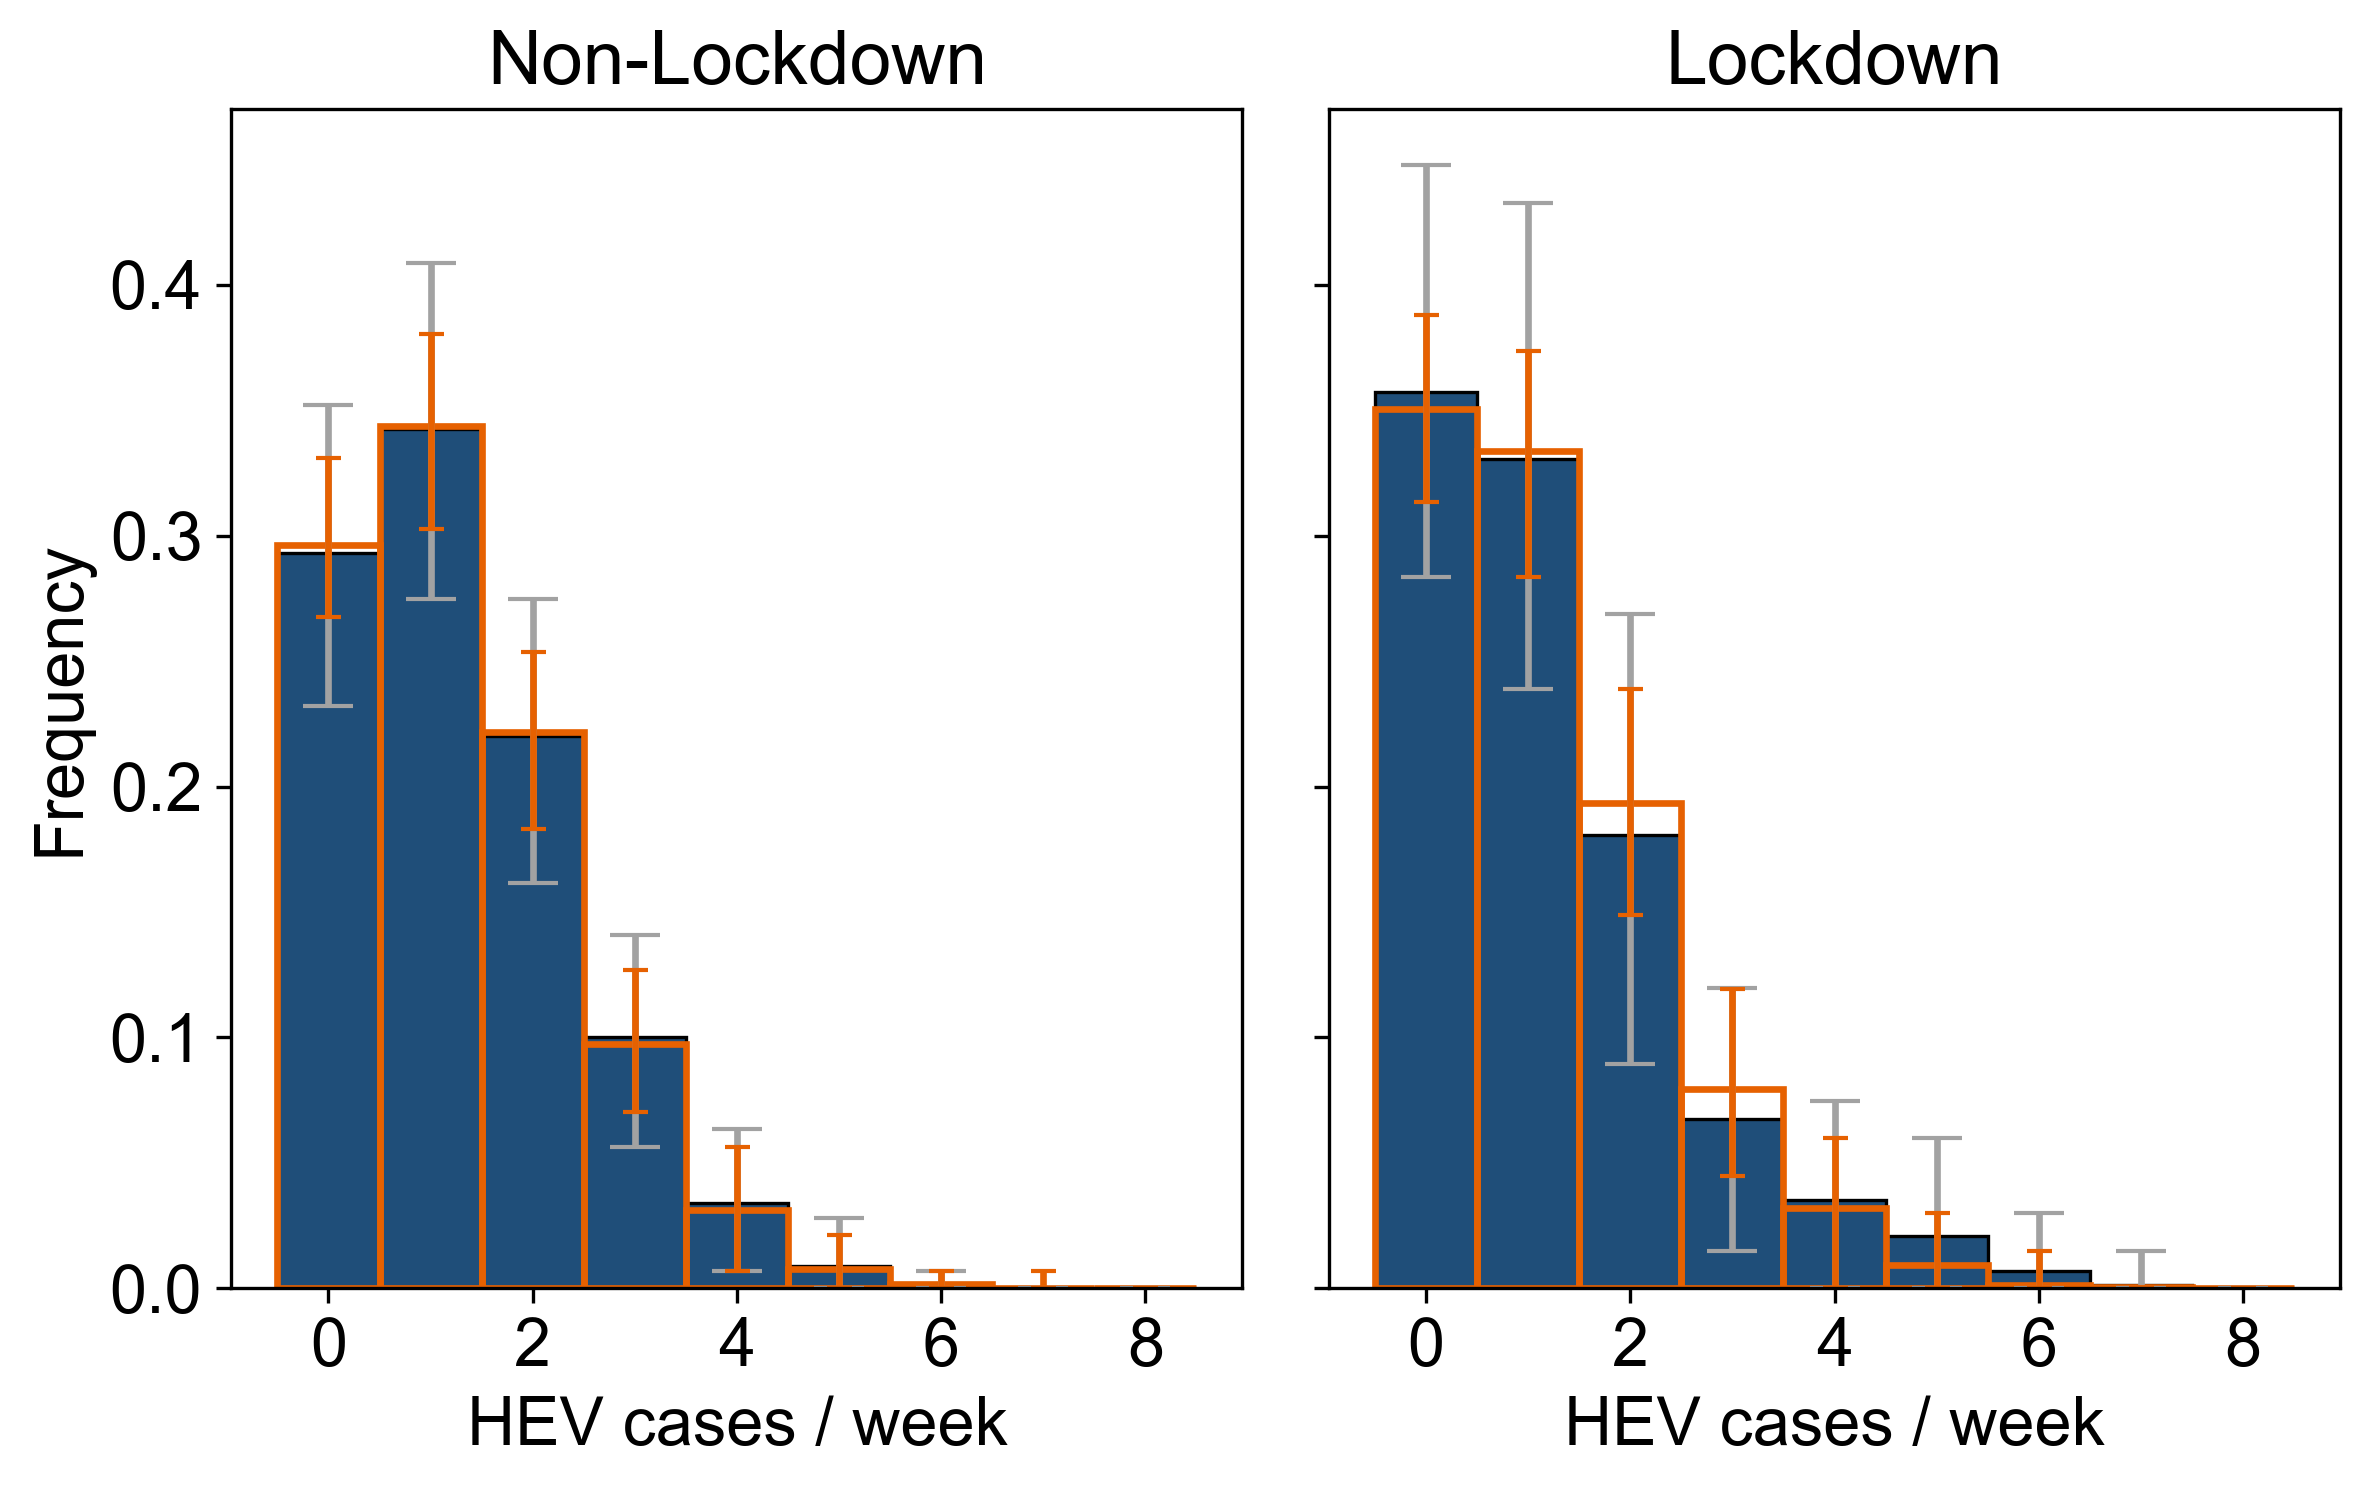

In [16]:
plt.style.use('default')
set_fontsize()

fig, axes = plt.subplots(figsize = (8.18,5.24), nrows=1, ncols=2, dpi=300, sharex=True, sharey=True)

counts = np.arange(min_count, max_count + 1)
display_names = {'Emergency': 'Lockdown', 'Non-Emergency': 'Non-Lockdown'}

for ax, cat in zip(axes, ['Non-Emergency', 'Emergency']):
    barw = 1
    
    m, lo, hi  = np.asarray(emp_mean[cat]), np.asarray(emp_lo[cat]), np.asarray(emp_hi[cat])
    ax.bar(counts, m, width=barw, color=darkblue, edgecolor='black', linewidth=0.8, label='Empirical data – mean')
    lower_err = np.maximum(0, m - lo)
    upper_err = np.maximum(0, hi - m)
    yerr_emp  = np.vstack([lower_err, upper_err])
    ax.errorbar(counts, m, yerr=yerr_emp, fmt='none', ecolor=medium_grey, elinewidth=1.6, capsize=5, label='Empirical data – 95% SI')

    ssub = sim[sim['Category'] == cat]
    sim_mat = (ssub.groupby(['particle', 'cases']).size().unstack(fill_value=0).reindex(columns=counts, fill_value=0).to_numpy())
    sim_mat = sim_mat / sim_mat.sum(axis=1, keepdims=True)
    sim_mean = sim_mat.mean(axis=0)
    sim_lo = np.percentile(sim_mat, 2.5, axis=0)
    sim_hi = np.percentile(sim_mat, 97.5, axis=0)
    lower_err = np.maximum(0, sim_mean - sim_lo)
    upper_err = np.maximum(0, sim_hi - sim_mean)
    yerr = np.vstack([lower_err, upper_err])
    ax.bar(counts, sim_mean, width=barw, facecolor='none', edgecolor=orange, linewidth=1.6, label="Sim. result (gen. 8) – mean")
    ax.errorbar(counts, sim_mean, yerr=yerr, fmt='none', ecolor=orange, elinewidth=1.6, capsize=3, label="Sim. result (gen. 8) – 95% SI")

    ax.set_title(display_names.get(cat, cat))
    ax.set_xlabel("HEV cases / week")
    ax.set_ylabel("")
    ax.set_xticks([0, 2, 4, 6, 8])

axes[0].set_ylabel("Frequency")
# handles, labels = axes[0].get_legend_handles_labels()
# order = [2, 1, 0]
# handles = [handles[i] for i in order]
# labels = [labels[i] for i in order]
# 
# fig.legend(handles, labels, loc='lower center', ncol=2, frameon=True, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig(f"{plot_path}/dist-fits.png", dpi=300)
plt.show()

In [21]:
def posterior_to_plot_1d(pop_num, x_var, x_min, x_max, num_x):
    df, w = history.get_distribution(0, pop_num)
    post = pyabc.visualization.kde.kde_1d(df, w, x = x_var, xmin = x_min, xmax = x_max, numx = num_x)
    post_list = list(map(list, zip(*list(post))))
    return pd.DataFrame(post_list, columns = ["x", "prob"])

In [22]:
pop0_ld = posterior_to_plot_1d(pop_num = 0, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop2_ld = posterior_to_plot_1d(pop_num = 2, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop5_ld = posterior_to_plot_1d(pop_num = 5, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop6_ld = posterior_to_plot_1d(pop_num = 6, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)
pop7_ld = posterior_to_plot_1d(pop_num = 7, x_var = "ld", x_min = 0, x_max = 2, num_x = 2001)

In [23]:
def plot_group(ax, dfs, xticks=None, xticklabels=None):
    set_fontsize()
    colors = [lightest_grey, lightgrey, medium_grey, darkgrey, orange]
    for d, c in zip(dfs, colors):
        sns.lineplot(data = d, x="x", y="prob", color=c, ax=ax)

    max_y = max(df['prob'].max() for df in dfs) * 1.05
    min_y = min(df['prob'].min() for df in dfs)

    ax.set(ylim=(min_y, max_y))
    ax.set_yticks([min_y, (min_y + max_y) / 2, max_y])
    ax.set(xlabel=None, ylabel=None, yticklabels=[])

    if xticks is not None:
        ax.set_xticks(xticks)
    if xticklabels is not None:
        ax.set_xticklabels(xticklabels)

    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.margins(x=0, y=0)

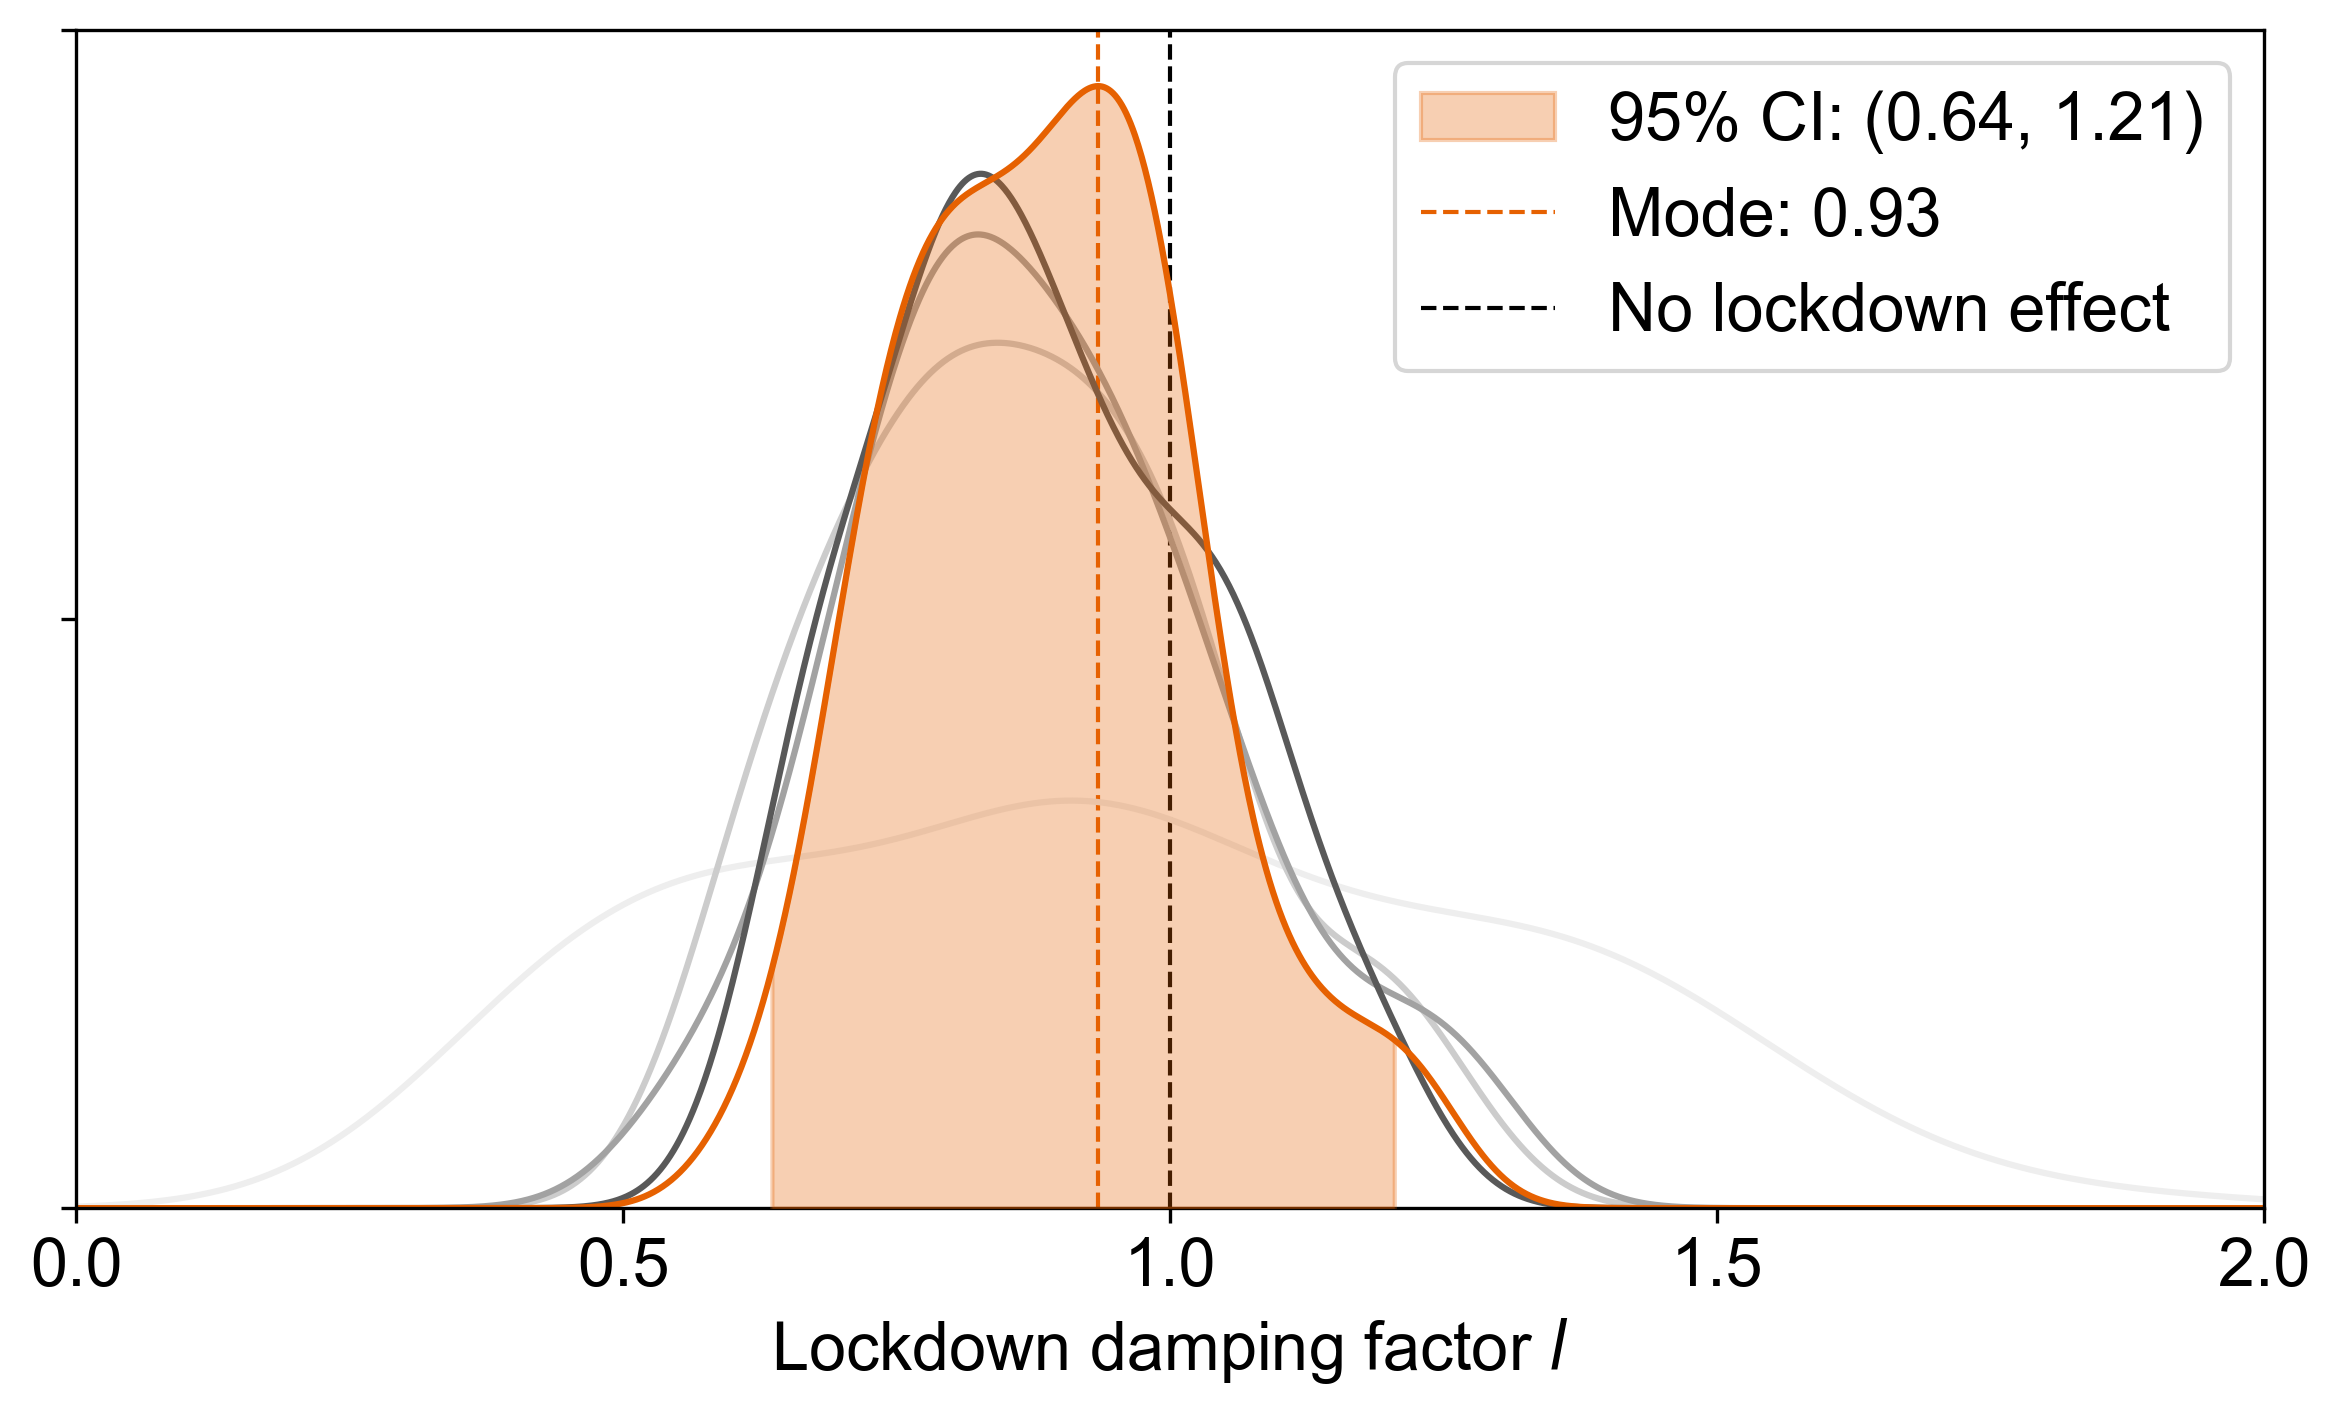

In [24]:
plt.style.use('default')
set_fontsize()

fig, ax = plt.subplots(figsize=(8.08, 5), dpi=300)

x = pop7_ld['x'].to_numpy()
y = pop7_ld['prob'].to_numpy()
x_mode = x[np.argmax(y)]
cdf = np.cumsum(y)
cdf = cdf / cdf[-1]
q_lo, q_hi = np.interp([0.025, 0.975], cdf, x)
mask = (pop7_ld["x"] >= q_lo) & (pop7_ld["x"] <= q_hi)

ax.fill_between(pop7_ld["x"][mask], pop7_ld["prob"][mask], color=orange, alpha=0.3, label=f'95% CI: ({q_lo:.2f}, {q_hi:.2f})', zorder=5)
ax.axvline(x= x_mode, color=orange, linestyle='--', linewidth=1, label = f"Mode: {x_mode:.2f}")
ax.axvline(x=1, color='black', linestyle='--', linewidth=1, label = "No lockdown effect")
plot_group(ax, [pop0_ld, pop2_ld, pop5_ld, pop6_ld, pop7_ld],  xticks=[0, 0.5, 1, 1.5, 2])

ax.set_xlabel(r"Lockdown damping factor $l$")

# gen_handles = [
#     mlines.Line2D([], [], color=lightest_grey, label='Gen. 1'),
#     mlines.Line2D([], [], color=lightgrey, label='Gen. 3'),
#     mlines.Line2D([], [], color=medium_grey, label='Gen. 6'),
#     mlines.Line2D([], [], color=darkgrey, label='Gen. 7'),
#     mlines.Line2D([], [], color=orange, label='Gen. 8')
# ]
# 
# fig.legend(handles=gen_handles, loc='lower center', ncol=3, frameon=True)

plt.tight_layout()
plt.savefig(f"{plot_path}/posteriors.png", dpi=300)
plt.show()